# 04 · Model Evaluation & Prediction Results

**Part A, PageClassifier.** We refit the configuration selected in notebook 03 on all development
companies and evaluate it **once** on the held-out company. We report:
* headline metrics and generalisation (CV vs test);
* every algorithm on the test company;
* the confusion matrix, per-class report, and ROC / precision-recall curves;
* the binary task the KPI pipeline uses (is this page a statement?);
* a learning curve, the most informative features, error analysis, and sample predictions.

**Part B, KPI pipeline.** We measure the effect of KPI cleansing on accounting-identity violations versus
lost coverage, and the accuracy of reporting-unit detection.

**Outputs.** The deployable model goes to `models/page_classifier/`. The metrics go to
`ml/reports/metrics.json`, which the app's Model Lab reads.

In [1]:
import json
import time
import warnings
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, auc, average_precision_score, balanced_accuracy_score,
                             classification_report, cohen_kappa_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import label_binarize
from sklearn.svm import LinearSVC

from ml.paths import FIGURES_DIR, PROCESSED_DIR, RAW_DIR, REPO_DIR, REPORTS_DIR
from ml.models.page_clf import COARSE, COARSE_LABELS, STRUCT_FEATURES, candidates, features, load_pages, softmax_scores
from ml.preprocess.text_clean import normalize_unicode
from ml.preprocess.label_pages import label_document
from ml.preprocess.kpi_clean import clean_kpis, detect_report_unit_with_fallback

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 160)
METRICS = {"generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds")}


def save(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"04_{name}.png", dpi=130)
    plt.show()

## A1. Rebuild the selected configuration

In [2]:
selection = json.loads((REPORTS_DIR / "model_selection.json").read_text(encoding="utf-8"))
cfg = selection["final"]
print(json.dumps({k: cfg[k] for k in ("algorithm", "features", "imbalance", "params", "cv_macro_f1")}, indent=1))


def build_final():
    p = cfg["params"]
    feats = features("linear", **cfg["feature_flags"],
                     max_features=p["f__text__max_features"], ngram_range=tuple(p["f__text__ngram_range"]))
    cw = "balanced" if cfg["imbalance"] == "class weights" else None
    return Pipeline([("f", feats), ("m", LinearSVC(C=p["m__C"], class_weight=cw, max_iter=10000))])


pages = load_pages()
pages["coarse"] = pages.label.map(COARSE)
dev, test = pages[pages.split != "test"], pages[pages.split == "test"]
print(f"fit on {len(dev)} dev pages ({dev.company.nunique()} companies) → evaluate on {len(test)} pages of {test.company.unique().tolist()}")

t = time.time()
model = build_final().fit(dev, dev.coarse)
fit_s = time.time() - t
t = time.time()
pred = model.predict(test)
pred_ms = 1000 * (time.time() - t) / len(test)
print(f"fit {fit_s:.1f}s · inference {pred_ms:.2f} ms/page")

{
 "algorithm": "Linear SVM",
 "features": "text only",
 "imbalance": "class weights",
 "params": {
  "f__text__max_features": 15000,
  "f__text__ngram_range": [
   1,
   2
  ],
  "m__C": 0.02
 },
 "cv_macro_f1": 0.5039
}
fit on 1898 dev pages (3 companies) → evaluate on 301 pages of ['Bharti Airtel Ltd.']


fit 1.0s · inference 0.50 ms/page


## A2. Headline metrics on the held-out company

In [3]:
y_true = test.coarse.values
scores = softmax_scores(model, test)
classes = list(model.classes_)
Y = label_binarize(y_true, classes=classes)

headline = {
    "accuracy": accuracy_score(y_true, pred),
    "macro_f1": f1_score(y_true, pred, average="macro"),
    "weighted_f1": f1_score(y_true, pred, average="weighted"),
    "balanced_accuracy": balanced_accuracy_score(y_true, pred),
    "cohen_kappa": cohen_kappa_score(y_true, pred),
    "roc_auc_ovr_macro": roc_auc_score(Y, scores, average="macro"),
}
baseline_acc = (y_true == pd.Series(dev.coarse).mode()[0]).mean()
gen = pd.DataFrame({
    "CV (dev companies)": [cfg["cv_macro_f1"]],
    "Test (unseen company)": [headline["macro_f1"]],
}, index=["macro-F1"]).round(3)
display(pd.Series(headline, name="test").round(3).to_frame().T)
print(f"majority-class accuracy on test = {baseline_acc:.3f}")
gen

,accuracy,macro_f1,weighted_f1,balanced_accuracy,cohen_kappa,roc_auc_ovr_macro
test,0.641,0.513,0.663,0.54,0.491,0.836


majority-class accuracy on test = 0.392


,CV (dev companies),Test (unseen company)
macro-F1,0.504,0.513


In [4]:
support = pd.Series(y_true).value_counts().reindex(COARSE_LABELS).fillna(0).astype(int)
display(support.to_frame("test pages").T)
thin = support[support < 5].index.tolist()
if thin:
    print(f"CAUTION: {thin} have fewer than 5 test pages. Their per-class scores are not statistically meaningful; "
          "read macro-F1 with that in mind (one class with 1 page moves macro-F1 by up to 0.2).")

,statement,notes,auditor_report,narrative,other
test pages,1,118,15,127,40


CAUTION: ['statement'] have fewer than 5 test pages. Their per-class scores are not statistically meaningful; read macro-F1 with that in mind (one class with 1 page moves macro-F1 by up to 0.2).


**How to read these numbers.**
* **Cohen's κ** corrects accuracy for chance agreement. It is the fairest single number under heavy
  class imbalance.
* **ROC-AUC** measures *ranking* quality independent of the decision threshold. When it is high but
  F1 is lower, the model orders pages well but the default argmax threshold is not optimal for the rare
  classes.
* The labels are **weak labels**, so every score here is agreement with the heading rules on an unseen
  company. Section A8 shows that some "errors" are rule mistakes the model gets right.

## A3. Every algorithm on the test company (prediction results)

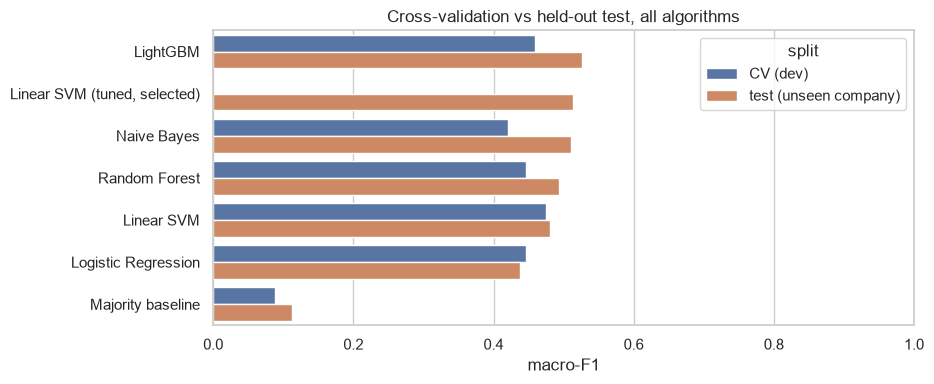

,model,macro_f1,accuracy,balanced_acc,kappa,cv_macro_f1
0,LightGBM,0.527,0.748,0.501,0.626,0.460
1,"Linear SVM (tuned, selected)",0.513,0.641,0.540,0.491,NaN
2,Naive Bayes,0.510,0.641,0.547,0.493,0.420
3,Random Forest,0.493,0.764,0.471,0.621,0.446
4,Linear SVM,0.481,0.588,0.472,0.451,0.474
5,Logistic Regression,0.438,0.542,0.429,0.400,0.446
6,Majority baseline,0.113,0.392,0.200,0.000,0.088


In [5]:
rows = []
for name, m in candidates().items():
    mm = clone(m).fit(dev, dev.coarse)
    p = mm.predict(test)
    rows.append({"model": name, "macro_f1": f1_score(y_true, p, average="macro"), "accuracy": accuracy_score(y_true, p),
                 "balanced_acc": balanced_accuracy_score(y_true, p), "kappa": cohen_kappa_score(y_true, p)})
rows.append({"model": "Linear SVM (tuned, selected)", "macro_f1": headline["macro_f1"], "accuracy": headline["accuracy"],
             "balanced_acc": headline["balanced_accuracy"], "kappa": headline["cohen_kappa"]})
test_cmp = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)

cv_scores = {r["model"]: r["macro_f1"] for r in selection["algorithms_5class"]}
test_cmp["cv_macro_f1"] = test_cmp.model.map(cv_scores)
fig, ax = plt.subplots(figsize=(9.5, 4))
plot = test_cmp.melt(id_vars="model", value_vars=["cv_macro_f1", "macro_f1"], var_name="split", value_name="macro-F1")
plot["split"] = plot.split.map({"cv_macro_f1": "CV (dev)", "macro_f1": "test (unseen company)"})
sns.barplot(data=plot, y="model", x="macro-F1", hue="split", ax=ax)
ax.set_xlim(0, 1)
ax.set_title("Cross-validation vs held-out test, all algorithms")
ax.set_ylabel("")
save("algos_test")
test_cmp.round(3)

In [6]:
sel_rank = int(test_cmp.index[test_cmp.model.str.contains("selected")][0]) + 1
best_test = test_cmp.iloc[0]
print(f"selected model ranks #{sel_rank} on the test company; best on test: {best_test.model} ({best_test.macro_f1:.3f})")
if best_test.model != test_cmp.model[test_cmp.model.str.contains('selected')].iloc[0]:
    print("→ We do NOT switch models based on this. The choice was made on cross-validation; picking the winner "
          "on the test set would turn the test set into a validation set and bias the reported score upwards. "
          f"The gap ({best_test.macro_f1 - headline['macro_f1']:.3f}) is also smaller than the CV fold std "
          "(notebook 03), so it is within noise.")

selected model ranks #2 on the test company; best on test: LightGBM (0.527)
→ We do NOT switch models based on this. The choice was made on cross-validation; picking the winner on the test set would turn the test set into a validation set and bias the reported score upwards. The gap (0.014) is also smaller than the CV fold std (notebook 03), so it is within noise.


## A4. Confusion matrix and per-class report

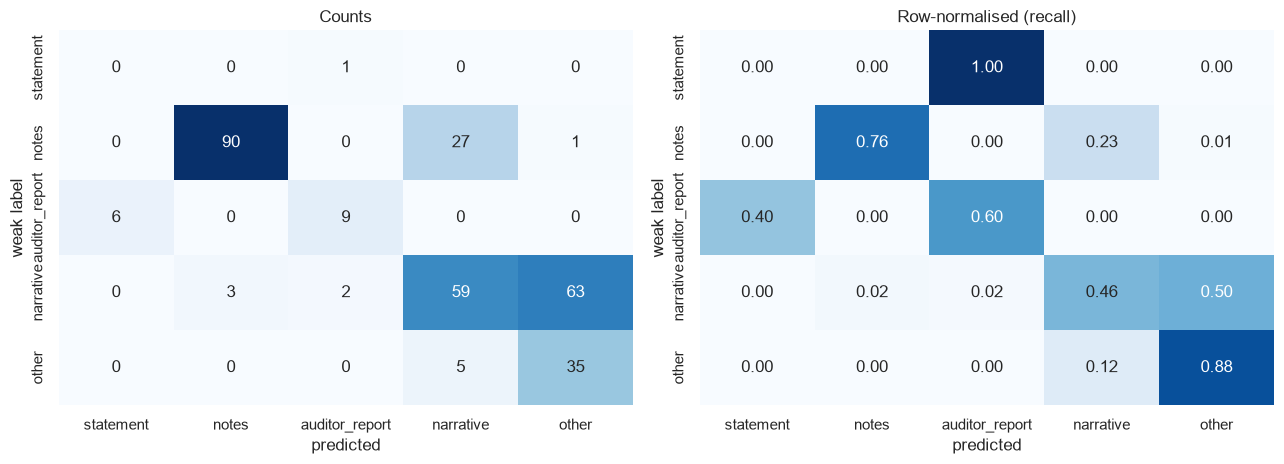

                precision    recall  f1-score   support

     statement      0.000     0.000     0.000         1
         notes      0.968     0.763     0.853       118
auditor_report      0.750     0.600     0.667        15
     narrative      0.648     0.465     0.541       127
         other      0.354     0.875     0.504        40

      accuracy                          0.641       301
     macro avg      0.544     0.540     0.513       301
  weighted avg      0.737     0.641     0.663       301



In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
cm = confusion_matrix(y_true, pred, labels=COARSE_LABELS)
cmn = confusion_matrix(y_true, pred, labels=COARSE_LABELS, normalize="true")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=COARSE_LABELS, yticklabels=COARSE_LABELS, ax=axes[0])
axes[0].set_title("Counts")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", cbar=False, xticklabels=COARSE_LABELS, yticklabels=COARSE_LABELS, ax=axes[1])
axes[1].set_title("Row-normalised (recall)")
for ax in axes:
    ax.set_xlabel("predicted")
    ax.set_ylabel("weak label")
save("confusion")

print(classification_report(y_true, pred, labels=COARSE_LABELS, digits=3, zero_division=0))
prec, rec, f1s, sup = precision_recall_fscore_support(y_true, pred, labels=COARSE_LABELS, zero_division=0)
per_class = pd.DataFrame({"precision": prec, "recall": rec, "f1": f1s, "support": sup}, index=COARSE_LABELS)

## A5. ROC and precision-recall curves (one-vs-rest)

For a rare class like `statement`, the PR curve is more informative than ROC. With very few positives,
ROC can look good while precision is poor.

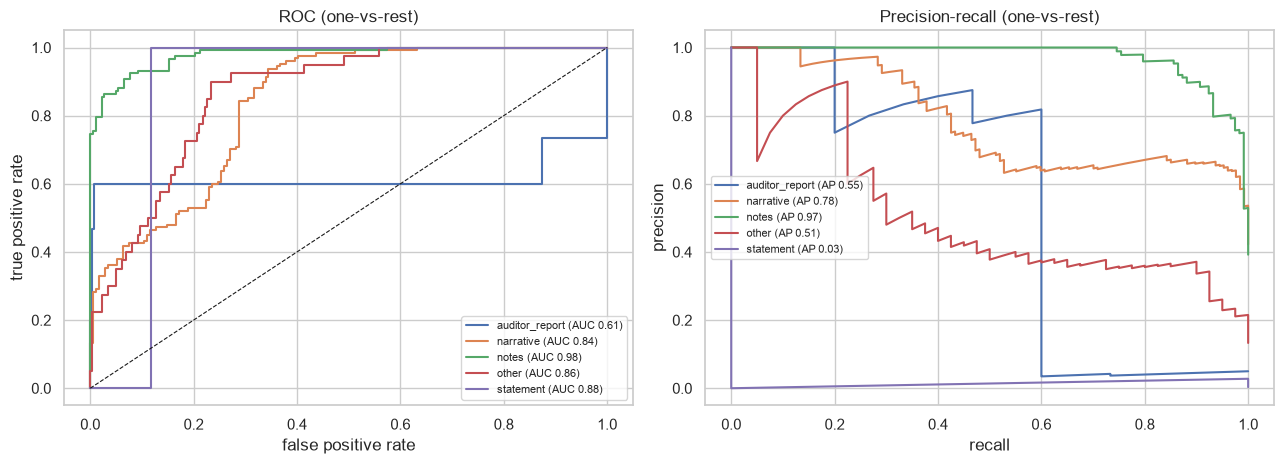

,roc_auc,average_precision,prevalence
auditor_report,0.615,0.550,0.050
narrative,0.837,0.783,0.422
notes,0.978,0.973,0.392
other,0.865,0.511,0.133
statement,0.883,0.028,0.003


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
curves = {}
for i, c in enumerate(classes):
    if Y[:, i].sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(Y[:, i], scores[:, i])
    pr, rc, _ = precision_recall_curve(Y[:, i], scores[:, i])
    ap = average_precision_score(Y[:, i], scores[:, i])
    curves[c] = {"roc_auc": auc(fpr, tpr), "average_precision": ap, "prevalence": Y[:, i].mean()}
    axes[0].plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.2f})")
    axes[1].plot(rc, pr, label=f"{c} (AP {ap:.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=.8)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (one-vs-rest)")
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall (one-vs-rest)")
for ax in axes:
    ax.legend(fontsize=8)
save("roc_pr")
pd.DataFrame(curves).T.round(3)

## A6. The downstream task: is this page a financial statement?

The KPI pipeline reads numbers and the reporting unit from **statement + notes** pages. This binary
view is the one that matters operationally.

In [9]:
fin = {"statement", "notes"}
b_true = np.isin(y_true, list(fin))
b_pred = np.isin(pred, list(fin))
fin_idx = [classes.index(c) for c in fin]
b_score = scores[:, fin_idx].sum(axis=1)
binary = {
    "precision": precision_recall_fscore_support(b_true, b_pred, average="binary")[0],
    "recall": precision_recall_fscore_support(b_true, b_pred, average="binary")[1],
    "f1": f1_score(b_true, b_pred),
    "roc_auc": roc_auc_score(b_true, b_score),
}
print("statement+notes vs rest on the test company:")
pd.Series(binary).round(3).to_frame("PageClassifier").T

statement+notes vs rest on the test company:


,precision,recall,f1,roc_auc
PageClassifier,0.909,0.756,0.826,0.937


## A7. Learning curve: would more data help?

We train on growing random fractions of the development pages and evaluate on the fixed test company.

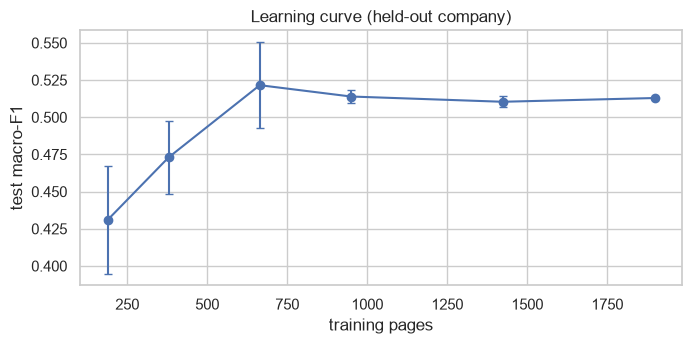

gain per +1,000 pages over the second half of the curve ≈ -0.001 macro-F1; the curve is within 0.01 of its maximum from ~664 pages on.


,train_pages,macro_f1,std
0,189,0.431,0.036
1,379,0.473,0.024
2,664,0.522,0.029
3,949,0.514,0.005
4,1423,0.510,0.004
5,1898,0.513,0.000


In [10]:
rng = np.random.default_rng(42)
lc = []
for frac in [0.1, 0.2, 0.35, 0.5, 0.75, 1.0]:
    vals = []
    for seed in range(3 if frac < 1 else 1):
        sub = dev.sample(frac=frac, random_state=seed) if frac < 1 else dev
        if sub.coarse.nunique() < len(COARSE_LABELS):
            continue
        p = build_final().fit(sub, sub.coarse).predict(test)
        vals.append(f1_score(y_true, p, average="macro"))
    lc.append({"train_pages": int(len(dev) * frac), "macro_f1": float(np.mean(vals)), "std": float(np.std(vals))})
lc = pd.DataFrame(lc)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(lc.train_pages, lc.macro_f1, yerr=lc["std"], marker="o", capsize=3)
ax.set(xlabel="training pages", ylabel="test macro-F1", title="Learning curve (held-out company)")
save("learning_curve")
slope = (lc.macro_f1.iloc[-1] - lc.macro_f1.iloc[len(lc) // 2]) / (lc.train_pages.iloc[-1] - lc.train_pages.iloc[len(lc) // 2]) * 1000
plateau = lc.train_pages[lc.macro_f1 >= lc.macro_f1.max() - 0.01].min()
print(f"gain per +1,000 pages over the second half of the curve ≈ {slope:+.3f} macro-F1; "
      f"the curve is within 0.01 of its maximum from ~{plateau} pages on.")
lc.round(3)

**Interpretation.** If the curve has plateaued, more pages *from the same companies* will not help.
The remaining error comes from (a) the noisy weak labels of the narrative/other classes and
(b) having only three training companies' templates. The next gains come from **more companies** and
**hand-corrected gold labels**, not from a bigger model.

## A8. What did the model learn? And where does it disagree with the rules?

In [11]:
svm = model.named_steps["m"]
vocab = model.named_steps["f"].get_feature_names_out()
top_terms = {}
for i, c in enumerate(svm.classes_):
    idx = np.argsort(svm.coef_[i])[::-1][:10]
    top_terms[c] = [v.split("__", 1)[1] for v in vocab[idx]]
pd.DataFrame(top_terms)

,auditor_report,narrative,notes,other,statement
0,opinion,yes,march,overview,statement
1,audit,details,march march,portfolio,profit
2,auditor,board,notes,portfolio overview,loss
3,hal,financial year,statements year,statutory reports,comprehensive income
4,shri,workers,ended march,reports,equity
5,auditor report,committee,year ended,ael,profit loss
6,act,activity project,ended,business,income
7,order,employees,notes standalone,strategic,accounting
8,key audit,report,note,sustainable,din
9,order applicable,yes yes,assets,reports esg,statement profit


In [12]:
err = test.assign(pred=pred, confidence=scores.max(axis=1))
wrong = err[err.pred != err.coarse]
print(f"{len(wrong)} disagreements out of {len(err)} pages")
(wrong.sort_values("confidence", ascending=False)
      .assign(snippet=lambda d: d.clean_text.str.replace(r"\s+", " ", regex=True).str[:110])
      [["page_number", "label", "label_source", "pred", "confidence", "snippet"]].head(12))

108 disagreements out of 301 pages


,page_number,label,label_source,pred,confidence,snippet
1118,216,auditor_report,carry,statement,0.424453,Consolidated Balance Sheet (All amounts are in...
1075,173,auditor_report,carry,statement,0.402945,Standalone Balance Sheet (All amounts are in m...
1120,218,auditor_report,carry,statement,0.379744,"For the year ended March 31, 2026 March 31, 20..."
1077,175,auditor_report,carry,statement,0.377961,"For the year ended March 31, 2026 March 31, 20..."
929,27,mda,carry,other,0.357580,"Our approach to Environmental, Social and Gove..."
928,26,mda,carry,other,0.335191,"We are also advancing adaptive technologies, i..."
917,15,mda,carry,other,0.334988,Message from the Executive Vice Chairman Build...
915,13,mda,carry,other,0.333588,Message from the Chairman Airtel: Building Ind...
927,25,mda,carry,other,0.332826,Material topics Material topics highlight the ...
916,14,mda,carry,other,0.332710,Our 5G Standalone readiness marks an important...


Reading the most confident disagreements is a manual audit of the weak labels. Pages where the model
confidently says *narrative* or *other* while the weak label says otherwise are often carry-forward
labels that ran past the end of a section, i.e. the **rule** is wrong. A hand-labelled gold sample of
test pages would turn this qualitative check into a corrected score; that is the next data-collection step.

## A9. Prediction results (sample)

In [13]:
sample = (err.sample(15, random_state=7).sort_values("page_number")
            .assign(snippet=lambda d: d.clean_text.str.replace(r"\s+", " ", regex=True).str[:80],
                    correct=lambda d: np.where(d.pred == d.coarse, "✓", "✗")))
sample[["page_number", "pred", "confidence", "coarse", "correct", "snippet"]].rename(columns={"coarse": "weak label"})

,page_number,pred,confidence,weak label,correct,snippet
940,38,other,0.304564,narrative,✗,Digital Innovations and Customer Delight Secur...
960,58,other,0.324516,other,✓,Innovations in Consumer Business services Incr...
969,67,other,0.320709,other,✓,"482.4 Mn 10,300+ 2,000+ 2,800+ 900,000+ Total ..."
984,82,other,0.321598,narrative,✗,Management Discussion and Analysis Overview Di...
1011,109,narrative,0.344188,narrative,✓,PRINCIPLE-WISE PERFORMANCE DISCLOSURE SECTION ...
1017,115,narrative,0.358068,narrative,✓,Principle Businesses should respect and promot...
1082,180,notes,0.263892,notes,✓,Notes to Standalone Financial Statements (All ...
1085,183,notes,0.313952,notes,✓,Notes to Standalone Financial Statements (All ...
1109,207,notes,0.291609,notes,✓,Notes to Standalone Financial Statements (All ...
1142,240,notes,0.300683,notes,✓,Notes to Consolidated Financial Statements (Al...


## A10. Deployable model

Having evaluated on the held-out company, we refit the same configuration on **all four companies**
and save it for the backend. Using all labelled data for the deployed model is standard practice; here
it also adds a fourth company template, which per A7 is what matters more than page count.
`backend/app/ml/page_classifier.py` loads it automatically.

In [14]:
model_dir = REPO_DIR / "models" / "page_classifier"
model_dir.mkdir(parents=True, exist_ok=True)
final = build_final().fit(pages, pages.coarse)
joblib.dump(final, model_dir / "model.joblib")
card = {
    "name": "PageClassifier", "version": datetime.now().strftime("%Y.%m.%d"),
    "task": "page-type classification of Indian annual-report pages",
    "labels": COARSE_LABELS, "config": cfg,
    "trained_on": {"pages": int(len(pages)), "companies": sorted(pages.company.unique().tolist())},
    "evaluation": {"held_out_company": test.company.unique().tolist(), **{k: round(v, 4) for k, v in headline.items()}},
    "inputs": "DataFrame with clean_text, head_text and " + ", ".join(STRUCT_FEATURES),
    "limitations": "Weak (rule-based) labels; 4 companies; narrative sub-sections merged; evaluate on gold labels before relying on per-class scores.",
}
(model_dir / "model_card.json").write_text(json.dumps(card, indent=1, default=float), encoding="utf-8")
print(f"saved {model_dir / 'model.joblib'} ({(model_dir / 'model.joblib').stat().st_size / 1e6:.1f} MB)")

saved D:\annual-report-analyzer-main\models\page_classifier\model.joblib (1.2 MB)


# Part B · KPI extraction pipeline

## B1. Reporting-unit detection accuracy

The **reference unit** of each report was verified by reading the unit declarations on its statement
pages (counts printed below; e.g. HAL prints "(₹ in Lakhs)" hundreds of times). We compare three
detectors:
* the whole report;
* statement pages chosen by the heading rules;
* statement pages chosen by the PageClassifier.

This is a small evaluation (6 reports), shown for completeness. The classifier saw the dev reports in
training; only Airtel is out-of-sample.

In [15]:
REFERENCE_UNIT = {  # verified from the statement-page declarations (see counts below)
    "ADARSH PLANT PROTECT LIMITED": "lakh", "Adani Enterprises Ltd.": "crore",
    "Bharti Airtel Ltd.": "million", "Hindustan Aeronautics Ltd.": "lakh",
}
raw = pd.read_json(RAW_DIR / "pages_raw.jsonl", lines=True)
unit_rows = []
for rid, g in raw.groupby("report_id", sort=False):
    g = g.sort_values("page_number")
    norm = [normalize_unicode(t) for t in g.raw_text]
    rule_fin = [t for t, (l, _) in zip(norm, label_document(norm)) if l in {"balance_sheet", "profit_loss", "cash_flow", "equity_changes", "notes"}]
    cls_in = pages[pages.report_id == rid].set_index("page_number")
    clf_pred = dict(zip(cls_in.index, final.predict(cls_in))) if len(cls_in) else {}
    clf_fin = [t for t, pn in zip(norm, g.page_number) if clf_pred.get(pn) in fin]
    whole = detect_report_unit_with_fallback([], norm, min_evidence=10**9)
    rules = detect_report_unit_with_fallback(rule_fin, norm)
    clf = detect_report_unit_with_fallback(clf_fin, norm)
    company = g.company.iat[0]
    unit_rows.append({"report": f"{company.split()[0]} {g.fiscal_year.iat[0]}", "reference": REFERENCE_UNIT[company],
                      "whole report": whole[0], "heading rules": rules[0], "PageClassifier": clf[0],
                      "statement-page evidence": clf[1]})
units = pd.DataFrame(unit_rows)
unit_acc = {c: float((units[c] == units.reference).mean()) for c in ["whole report", "heading rules", "PageClassifier"]}
display(units)
pd.Series(unit_acc, name="unit-detection accuracy").to_frame().T

,report,reference,whole report,heading rules,PageClassifier,statement-page evidence
0,ADARSH 2026,lakh,lakh,lakh,lakh,{'lakh': 30}
1,Adani 2026,crore,crore,crore,crore,{'crore': 306}
2,Adani 2025,crore,crore,crore,crore,{'crore': 340}
3,Bharti 2026,million,million,million,million,"{'million': 31, 'billion': 1, 'thousand': 4}"
4,Hindustan 2026,lakh,lakh,lakh,lakh,"{'crore': 1, 'lakh': 296}"
5,Hindustan 2025,lakh,lakh,lakh,lakh,"{'crore': 1, 'lakh': 291}"


,whole report,heading rules,PageClassifier
unit-detection accuracy,1.0,1.0,1.0


In [16]:
if len(set(unit_acc.values())) == 1:
    print(f"All three detectors agree ({list(unit_acc.values())[0]:.0%}) on these 6 reports. The statement-page restriction "
          "is a safeguard for reports whose narrative quotes figures in a different unit than the statements "
          "(e.g. HAL's narrative mentions '₹ crore' 23× while its statements are in lakh); "
          "this small sample does not contain a case where it changes the answer.")

All three detectors agree (100%) on these 6 reports. The statement-page restriction is a safeguard for reports whose narrative quotes figures in a different unit than the statements (e.g. HAL's narrative mentions '₹ crore' 23× while its statements are in lakh); this small sample does not contain a case where it changes the answer.


## B2. Effect of KPI cleansing

There is no gold KPI table, so we measure two observable quantities:
* **Accounting-identity violations**, i.e. values that break a constraint any real balance sheet or
  P&L satisfies:
  - Revenue from Operations is between 50% and 100% of Total Revenue;
  - a positive PAT is not more than 2× PBT;
  - Total Liabilities ≥ 1% of Total Assets;
  - stored ratios match the ratio recomputed from their components;
  - per-share and ratio values lie in plausible ranges;
  - money values are on a consistent unit scale across companies.
* **Coverage**, the share of KPIs still available. Cleansing trades coverage for correctness, and we
  report both sides.

In [17]:
kraw = pd.read_csv(RAW_DIR / "kpis_raw.csv")
report_units = {rid: REFERENCE_UNIT[c] for rid, c in raw.drop_duplicates("report_id")[["report_id", "company"]].values}
kclean, audit = clean_kpis(kraw, report_units)


def violations(df: pd.DataFrame, scaled: bool) -> dict:
    v = {"revenue_share": 0, "pat_vs_pbt": 0, "liabilities_share": 0, "ratio_mismatch": 0, "domain": 0, "unit_scale": 0}
    for rid, g in df.groupby("report_id"):
        val = dict(zip(g.name, g.value))
        get = lambda k: val.get(k, np.nan)
        rev, tot = get("Revenue from Operations"), get("Total Revenue")
        if pd.notna(rev) and pd.notna(tot) and tot > 0 and not (0.5 * tot <= rev <= 1.001 * tot):
            v["revenue_share"] += 1
        pbt, pat = get("Profit Before Tax (PBT)"), get("Profit After Tax (PAT) / Net Profit")
        if pd.notna(pbt) and pd.notna(pat) and pat > 0 and pbt < 0.5 * pat:
            v["pat_vs_pbt"] += 1
        tl, ta = get("Total Liabilities"), get("Total Assets")
        if pd.notna(tl) and pd.notna(ta) and ta > 0 and tl < 0.01 * ta:
            v["liabilities_share"] += 1
        for ratio, n, d in [("Current Ratio", "Current Assets", "Current Liabilities"),
                            ("Debt-to-Equity Ratio", "Debt (Total Borrowings)", "Total Equity / Shareholders Equity")]:
            r, nn, dd = get(ratio), get(n), get(d)
            if pd.notna(r) and pd.notna(nn) and pd.notna(dd) and dd > 0 and abs(r - nn / dd) > 0.25 * nn / dd:
                v["ratio_mismatch"] += 1
        eps = get("Earnings Per Share (EPS)")
        if pd.notna(eps) and not (-5000 <= eps <= 20000):
            v["domain"] += 1
        de = get("Debt-to-Equity Ratio")
        if pd.notna(de) and not (0 <= de <= 30):
            v["domain"] += 1
        # unit scale: a report's Total Revenue expressed in ₹ crore must be < ₹10 lakh crore (largest Indian company ≈ ₹10 L Cr)
        if pd.notna(tot) and tot > 1_000_000:
            v["unit_scale"] += 1
    return v


before, after = violations(kraw, False), violations(kclean, True)
b2 = pd.DataFrame({"before cleansing": before, "after cleansing": after})
b2.loc["TOTAL"] = b2.sum()
coverage = {"before": float(kraw.value.notna().mean()), "after": float(kclean[kclean.report_id.isin(kraw.report_id)].value.notna().mean())}
display(b2)
print(f"coverage: {coverage['before']:.1%} → {coverage['after']:.1%} of KPI rows hold a value "
      f"(+{int((audit.rule == 'derived').sum())} ratios derived)")

,before cleansing,after cleansing
revenue_share,5,0
pat_vs_pbt,3,0
liabilities_share,2,0
ratio_mismatch,4,0
domain,3,0
unit_scale,3,0
TOTAL,20,0


coverage: 100.0% → 85.6% of KPI rows hold a value (+5 ratios derived)


**Caveat.** These checks are the same identities the cleansing rules enforce, so "0 after" is expected
by construction. The informative results are:
* how many violations the raw extractor produced, i.e. how often it was wrong in a detectable way;
* the **coverage cost**: the share of values removed rather than corrected.

Removed values show up in the app as *rejected*, with the reason, instead of silently wrong numbers.

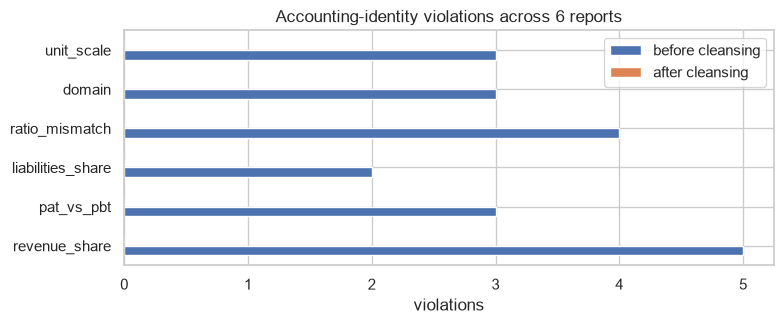

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.4))
b2.drop(index="TOTAL").plot.barh(ax=ax)
ax.set_title("Accounting-identity violations across 6 reports")
ax.set_xlabel("violations")
save("kpi_cleansing")

## Write metrics for the Model Lab

In [19]:
METRICS["models"] = {
    "page_classifier": {
        "status": "trained", "config": cfg, "test_company": test.company.unique().tolist(),
        "test": {k: round(float(v), 4) for k, v in headline.items()},
        "cv_macro_f1": cfg["cv_macro_f1"], "fit_seconds": round(fit_s, 2), "ms_per_page": round(pred_ms, 3),
        "statement_detection": {k: round(float(v), 4) for k, v in binary.items()},
    },
    "kpi_cleaning": {"status": "active", "unit_detection_accuracy": unit_acc, "violations": {k: {kk: int(vv) for kk, vv in v.items()} for k, v in b2.to_dict().items()},
                     "coverage": coverage},
    "kpi_ner": {"status": "pending"}, "finsumm": {"status": "pending"},
}
METRICS["comparisons"] = [
    {"title": "Algorithms · 5-class · leave-one-company-out CV", "metric": "macro-F1",
     "results": [{"model": r["model"], "score": round(r["macro_f1"], 4), "std": round(r["macro_f1_std"], 4)} for r in selection["algorithms_5class"]]},
    {"title": "Algorithms · held-out company (test)", "metric": "macro-F1",
     "results": [{"model": r.model, "score": round(r.macro_f1, 4)} for r in test_cmp.itertuples()]},
    {"title": "Algorithms · 10-class · leave-one-company-out CV", "metric": "macro-F1",
     "results": [{"model": r["model"], "score": round(r["macro_f1"], 4), "std": round(r["macro_f1_std"], 4)} for r in selection["algorithms_10class"]]},
    {"title": "Class-imbalance handling (Linear SVM, CV)", "metric": "macro-F1",
     "results": [{"model": r["model"], "score": round(r["macro_f1"], 4)} for r in selection["imbalance"]]},
    {"title": "Feature ablation · Linear SVM (CV)", "metric": "macro-F1",
     "results": [{"model": r["features"], "score": round(r["macro_f1"], 4)} for r in selection["feature_ablation"] if r["family"] == "Linear SVM"]},
]
METRICS["page_classifier"] = {
    "labels": COARSE_LABELS,
    "confusion": cm.tolist(),
    "per_class": per_class.reset_index(names="label").round(4).to_dict("records"),
    "curves": {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in curves.items()},
    "learning_curve": lc.round(4).to_dict("records"),
    "top_terms": top_terms,
    "predictions_sample": sample[["page_number", "pred", "confidence", "coarse", "snippet"]].round(3).rename(columns={"coarse": "weak_label"}).to_dict("records"),
    "selection": {"justification": cfg["justification"], "gridsearch_top": selection["gridsearch_top"]},
}
METRICS["unit_detection"] = units.drop(columns="statement-page evidence").to_dict("records")


def to_json_safe(o):
    if isinstance(o, dict):
        return {str(k): to_json_safe(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_json_safe(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return o


(REPORTS_DIR / "metrics.json").write_text(json.dumps(to_json_safe(METRICS), indent=1, ensure_ascii=False, allow_nan=False), encoding="utf-8")
print("wrote metrics.json:", list(METRICS))

wrote metrics.json: ['generated_at', 'models', 'comparisons', 'page_classifier', 'unit_detection']


## Summary

| Question | Where answered |
|---|---|
| How well does the selected model generalise to an unseen company? | A2 (CV vs test, κ, ROC-AUC) |
| Is it better than the alternatives on unseen data too? | A3 (all algorithms on test) |
| Which classes work, which don't? | A4 confusion matrix, A5 ROC/PR curves |
| Does it serve the KPI pipeline? | A6 statement detection, B1 unit detection |
| What limits it, and what would help? | A7 learning curve, A8 audit of the weak labels |
| Did KPI cleansing improve the data? | B2 violations vs coverage |